# Are jerk/jump annotations caught by the SPINDLE noise threshold?

For every annotation whose label contains **`jerk`** or **`jump`**, look up the
SPINDLE epoch it falls in and check whether that epoch's `noise_probs` clears
the noise threshold (i.e. would be masked out as noise).

Matching: each annotation file's stem is a prefix of its SPINDLE CSV filename.

Results are reported **overall**, **by SPINDLE epoch state** (`rawstate`), and
**by the state word parsed from the annotation label**.

In [55]:
from pathlib import Path
import csv
import pandas as pd

SPINDLE_DIR = Path("/media/matt/Data_A/leah/Stxbp1_characterization/spindle_outputs/LFC_RSC")
ANNOT_DIR = Path("/media/matt/Data_A/leah/Stxbp1_characterization/annotations")

# An epoch counts as 'noise' (i.e. the jerk/jump is 'caught') when
# noise_probs >= THRESHOLD. 0.5 is the project default (spindle_noise()).
THRESHOLD = 0.5
WINSIZE = 4          # SPINDLE epoch length in seconds
KEYWORDS = ("jerk", "jump")

## Parsers

In [56]:
def load_spindle(path):
    """Return a DataFrame indexed by epoch with noise_probs and rawstate."""
    df = pd.read_csv(path, usecols=["noise_probs", "rawstate"])
    df.index.name = "epoch"
    return df


def load_jerk_jump_annotations(path):
    """Return [(time_from_start_sec, label), ...] for jerk/jump annotations.

    Pinnacle .txt: a few header lines, then a tab-separated table whose header
    row contains 'Time From Start' and 'Annotation'. Times are seconds from the
    start of recording, which aligns with SPINDLE epoch 0.
    """
    rows = []
    with open(path, newline="") as f:
        reader = csv.reader(f, delimiter="\t")
        header = None
        for parts in reader:
            if header is None:
                if "Time From Start" in parts and "Annotation" in parts:
                    header = parts
                    t_idx = header.index("Time From Start")
                    a_idx = header.index("Annotation")
                continue
            if len(parts) <= max(t_idx, a_idx):
                continue
            label = parts[a_idx]
            if any(kw in label.lower() for kw in KEYWORDS):
                rows.append((float(parts[t_idx]), label.strip()))
    return rows


# Canonical sleep/wake state parsed out of a messy annotation label, e.g.
# 'Jerk - nspk - trans - NREM' -> 'NREM'. Priority order: pick the most
# specific scored state if several words are present.
_LABEL_STATES = [
    ("nrem", "NREM"),
    ("rem", "REM"),
    ("qw", "QW"),
    ("awake", "awake"),
    ("wake", "awake"),
]


def label_state(label):
    low = label.lower()
    for needle, canon in _LABEL_STATES:
        if needle in low:
            return canon
    return "unknown"

## Match files and build one row per jerk/jump annotation

In [57]:
spindle_files = sorted(SPINDLE_DIR.glob("*_SPINDLE_labels.csv"))
annot_files = sorted(ANNOT_DIR.glob("*.txt"))

# Animal ID = leading token of the stem, before the first '_' (e.g. "Mice-1248").
def animal_id(path):
    return path.stem.split("_", 1)[0]

spindle_by_animal = {}
for s in spindle_files:
    spindle_by_animal.setdefault(animal_id(s), s)

records = []
unmatched = []
for annot_path in annot_files:
    stem = annot_path.stem
    spindle_path = spindle_by_animal.get(animal_id(annot_path))
    if spindle_path is None:
        unmatched.append(annot_path.name)
        continue
    spindle = load_spindle(spindle_path)
    n_epochs = len(spindle)
    for t, label in load_jerk_jump_annotations(annot_path):
        epoch = int(t // WINSIZE)
        if epoch >= n_epochs:
            continue  # annotation past the end of the scored recording
        noise = float(spindle.iloc[epoch]["noise_probs"])
        records.append(
            {
                "file": stem.split('_')[0],
                "time_s": t,
                "epoch": epoch,
                "label": label,
                "noise_prob": noise,
                "caught": noise >= THRESHOLD,
                "spindle_state": spindle.iloc[epoch]["rawstate"],
                "label_state": label_state(label),
            }
        )

df = pd.DataFrame(records)
print(f"matched annotation files: {len(annot_files) - len(unmatched)} / {len(annot_files)}")
if unmatched:
    print("unmatched:", unmatched)
print(f"jerk/jump annotations: {len(df)}")
df.head()

matched annotation files: 24 / 24
jerk/jump annotations: 1047


,file,time_s,epoch,label,noise_prob,caught,spindle_state,label_state
0,Mice-1248,137365.545,34341,Jerk - nspk - sleep - NREM,0.046454,False,n,NREM
1,Mice-1248,147415.673,36853,Jerk - spike - sleep - NREM,0.024470,False,n,NREM
2,Mice-1248,147463.397,36865,Jerk - spike - trans - NREM,0.220997,False,n,NREM
3,Mice-1248,178123.451,44530,Jerk - spike - trans - NREM,0.012686,False,n,NREM
4,Mice-1248,240947.264,60236,Jerk - spike - sleep - NREM,0.004004,False,n,NREM


## Overall

In [58]:
total = len(df)
caught = int(df["caught"].sum())
print(f"THRESHOLD = {THRESHOLD}")
print(f"caught {caught} / {total} jerk-or-jump annotations "
      f"({caught / total:.1%})" if total else "no annotations")

THRESHOLD = 0.5
caught 418 / 1047 jerk-or-jump annotations (39.9%)


## By SPINDLE epoch state (`rawstate`)

In [59]:
def breakdown(df, by):
    g = df.groupby(by)["caught"].agg(total="size", caught="sum")
    g["pct_caught"] = (g["caught"] / g["total"] * 100).round(1)
    return g

breakdown(df, "spindle_state")

,total,caught,pct_caught
spindle_state,,,
n,444,92,20.7
r,174,55,31.6
w,429,271,63.2


## By annotation-label state

State word parsed heuristically from the label text (see `label_state`).

In [60]:
breakdown(df, "label_state")

,total,caught,pct_caught
label_state,,,
NREM,452,152,33.6
QW,87,48,55.2
REM,231,93,40.3
awake,159,71,44.7
unknown,118,54,45.8


## Per file

One row per recording: jerk/jump count, how many were caught, and the catch rate.

In [61]:
per_file = breakdown(df, "file").sort_values("pct_caught", ascending=False)
per_file

,total,caught,pct_caught
file,,,
Mice-C561,61,42,68.9
Mice-C567,9,6,66.7
Mice-1282,11,7,63.6
Mice-1286,19,12,63.2
Mice-C317,14,8,57.1
Mice-C269,66,35,53.0
Mice-C348,18,9,50.0
Mice-C259,89,43,48.3
Mice-C268,94,44,46.8


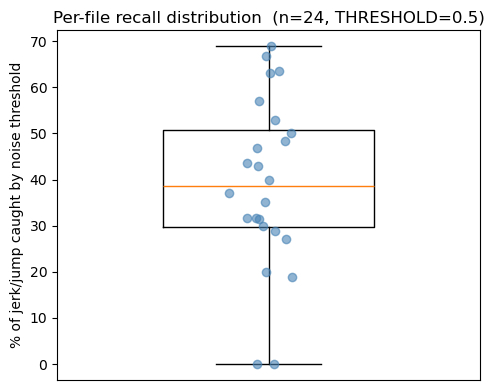

In [62]:
import matplotlib.pyplot as plt

recall = per_file["pct_caught"]

fig, ax = plt.subplots(figsize=(5, 4))
#ax.boxplot(recall, vert=True, widths=0.5, showmeans=True)
ax.boxplot(recall, vert=True, widths=0.5)

# jittered points so each recording is visible
import numpy as np
x = np.random.default_rng(0).normal(1, 0.04, size=len(recall))
ax.scatter(x, recall, alpha=0.6, color="steelblue", zorder=3)
#ax.set_ylabel("per-file recall (% of jerk/jump caught by noise threshold)")
ax.set_ylabel("% of jerk/jump caught by noise threshold")
ax.set_title(f"Per-file recall distribution  (n={len(recall)}, THRESHOLD={THRESHOLD})")
#ax.set_ylim(0, 100)
ax.set_xticks([])
fig.tight_layout()
plt.show()

In [63]:
breakdown(df[df['file']=='Mice-C309'], "spindle_state")

,total,caught,pct_caught
spindle_state,,,
n,3,0,0.0
r,17,0,0.0
w,5,0,0.0


In [64]:
df[df['file']=='Mice-C309']

,file,time_s,epoch,label,noise_prob,caught,spindle_state,label_state
587,Mice-C309,47704.582,11926,Jerk - nspk - sleep - NREM,0.013152,False,n,NREM
588,Mice-C309,62328.079,15582,Jerk - nspk -trans - REM,0.212731,False,r,REM
589,Mice-C309,137449.525,34362,Jump - REM,0.143211,False,r,REM
590,Mice-C309,146091.697,36522,Jerk - nspk - trans - NREM,0.094529,False,r,NREM
591,Mice-C309,146731.738,36682,Jerk - nspk - trans - NREM,0.112209,False,n,NREM
592,Mice-C309,146942.400,36735,Jump - REM,0.141336,False,r,REM
593,Mice-C309,150815.150,37703,Jump - REM,0.109229,False,r,REM
594,Mice-C309,151737.288,37934,Jump - REM,0.429966,False,r,REM
595,Mice-C309,153613.355,38403,Jerk - nspk - awake,0.168072,False,w,awake
596,Mice-C309,156888.927,39222,Jerk - nspk - trans - REM,0.053772,False,r,REM


### Per-file recall by state

Each box is the distribution of per-file recall for one state (one point per
recording that has jerk/jump annotations in that state). Left panel groups by
the SPINDLE epoch state; right panel by the annotation-label state.

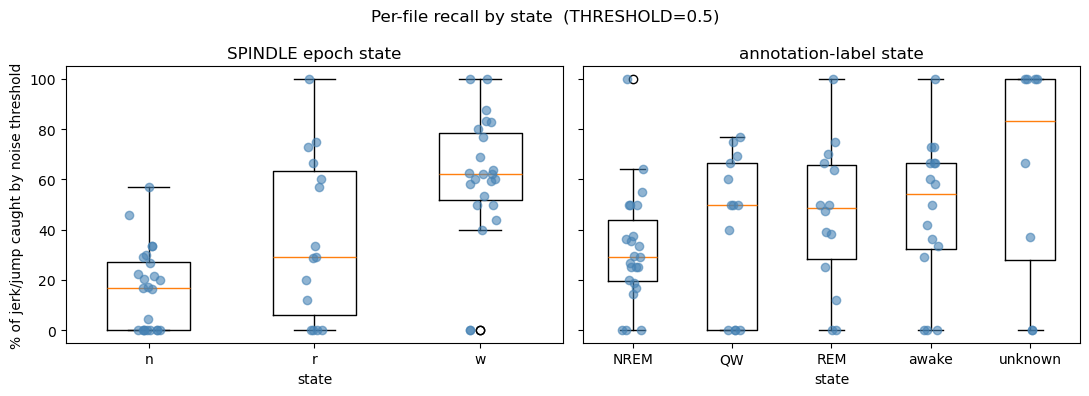

In [65]:
import numpy as np
import matplotlib.pyplot as plt

def recall_by(state_col):
    """Per-file recall (% caught) indexed by (state, file)."""
    return df.groupby([state_col, "file"])["caught"].mean().mul(100)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
rng = np.random.default_rng(0)
for ax, col, title in [
    (axes[0], "spindle_state", "SPINDLE epoch state"),
    (axes[1], "label_state", "annotation-label state"),
]:
    g = recall_by(col)
    states = sorted(df[col].unique())
    data = [g.loc[s].values for s in states]
    ax.boxplot(data, widths=0.5)
    for i, vals in enumerate(data, start=1):
        ax.scatter(rng.normal(i, 0.05, size=len(vals)), vals,
                   alpha=0.6, color="steelblue", zorder=3)
    ax.set_xticks(range(1, len(states) + 1))
    ax.set_xticklabels(states)
    ax.set_title(title)
    ax.set_xlabel("state")

axes[0].set_ylabel("% of jerk/jump caught by noise threshold")
#axes[0].set_ylim(0, 100)
fig.suptitle(f"Per-file recall by state  (THRESHOLD={THRESHOLD})")
fig.tight_layout()
plt.show()

### Pooled per-state view

Instead of one point per file, pool every jerk/jump annotation together and take
a single recall per state (annotation-weighted, so busy recordings count more).
Bar height is % caught; the label shows caught / total.

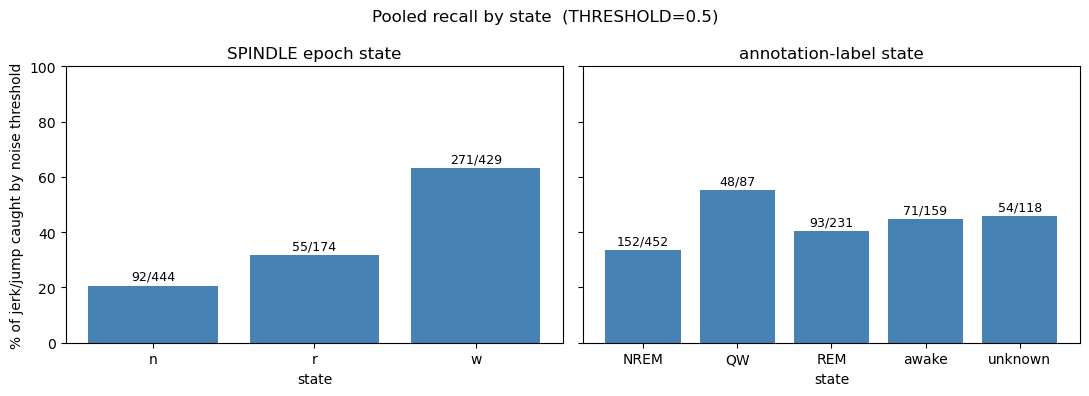

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col, title in [
    (axes[0], "spindle_state", "SPINDLE epoch state"),
    (axes[1], "label_state", "annotation-label state"),
]:
    g = breakdown(df, col)  # total, caught, pct_caught per state
    bars = ax.bar(g.index, g["pct_caught"], color="steelblue")
    for bar, (_, row) in zip(bars, g.iterrows()):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                f"{int(row['caught'])}/{int(row['total'])}",
                ha="center", va="bottom", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel("state")

axes[0].set_ylabel("% of jerk/jump caught by noise threshold")
axes[0].set_ylim(0, 100)
fig.suptitle(f"Pooled recall by state  (THRESHOLD={THRESHOLD})")
fig.tight_layout()
plt.show()

### Split by event type (jerk vs jump)

Pooled recall broken out by whether the label says **jerk** or **jump**. Left
panel is overall; right panel is grouped by SPINDLE epoch state.

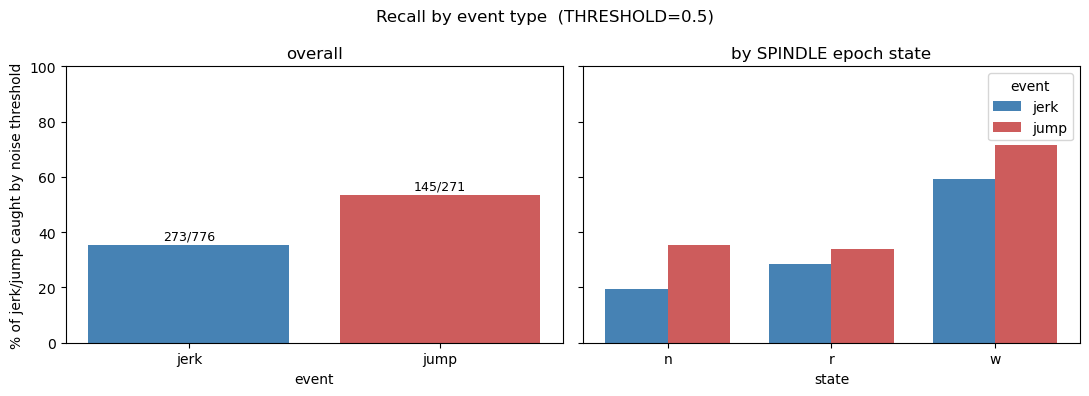

In [67]:
# event type from the label; "jerk" wins if a label somehow mentions both
dfe = df.copy()
dfe["event"] = np.where(dfe["label"].str.lower().str.contains("jerk"), "jerk", "jump")

event_order = ["jerk", "jump"]
colors = {"jerk": "steelblue", "jump": "indianred"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

# --- overall ---
g = breakdown(dfe, "event").reindex(event_order)
bars = axes[0].bar(g.index, g["pct_caught"], color=[colors[e] for e in g.index])
for bar, (_, row) in zip(bars, g.iterrows()):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                 f"{int(row['caught'])}/{int(row['total'])}",
                 ha="center", va="bottom", fontsize=9)
axes[0].set_title("overall")
axes[0].set_xlabel("event")

# --- grouped by SPINDLE state ---
states = sorted(dfe["spindle_state"].unique())
x = np.arange(len(states))
width = 0.38
for i, ev in enumerate(event_order):
    sub = dfe[dfe["event"] == ev]
    g = breakdown(sub, "spindle_state").reindex(states)
    axes[1].bar(x + (i - 0.5) * width, g["pct_caught"], width,
                label=ev, color=colors[ev])
axes[1].set_xticks(x)
axes[1].set_xticklabels(states)
axes[1].set_title("by SPINDLE epoch state")
axes[1].set_xlabel("state")
axes[1].legend(title="event")

axes[0].set_ylabel("% of jerk/jump caught by noise threshold")
axes[0].set_ylim(0, 100)
fig.suptitle(f"Recall by event type  (THRESHOLD={THRESHOLD})")
fig.tight_layout()
plt.show()

### Split by event type, per file

Same jerk-vs-jump split, but each point is one recording's recall (not pooled).
Left panel is overall; right panel groups by SPINDLE epoch state.

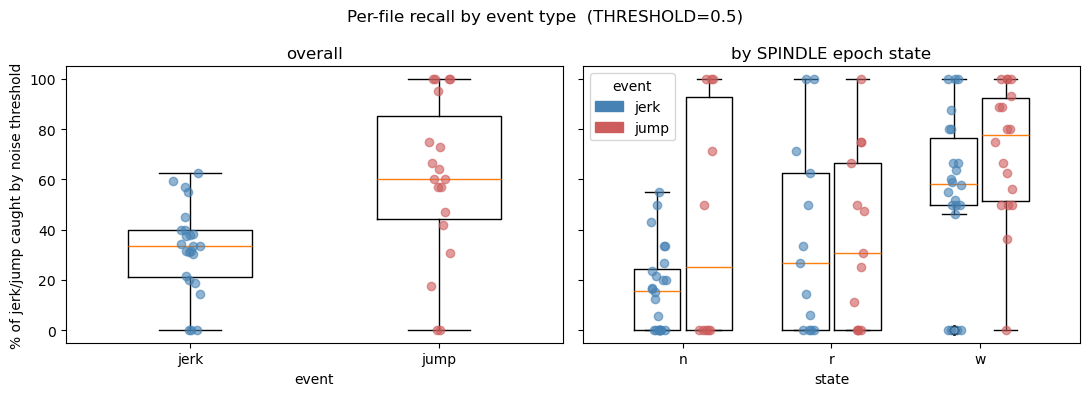

In [70]:
from matplotlib.patches import Patch

# dfe / event / colors / event_order come from the pooled cell above
rng = np.random.default_rng(0)

def _box(ax, vals, pos, color, width):
    """Draw one box at pos with jittered points; skip if empty."""
    if len(vals) == 0:
        return
    ax.boxplot(vals, positions=[pos], widths=width)
    ax.scatter(rng.normal(pos, 0.03, len(vals)), vals,
               alpha=0.6, color=color, zorder=3)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

# --- overall: one box per event, points = per-file recall ---
g = dfe.groupby(["event", "file"])["caught"].mean().mul(100)
for i, ev in enumerate(event_order, start=1):
    _box(axes[0], g.loc[ev].values, i, colors[ev], 0.5)
axes[0].set_xticks(range(1, len(event_order) + 1))
axes[0].set_xticklabels(event_order)
axes[0].set_title("overall")
axes[0].set_xlabel("event")

# --- grouped by SPINDLE state, jerk vs jump side by side ---
states = sorted(dfe["spindle_state"].unique())
centers = np.arange(len(states)) + 1
width = 0.35
g2 = dfe.groupby(["spindle_state", "event", "file"])["caught"].mean().mul(100)
for ei, ev in enumerate(event_order):
    offset = (ei - 0.5) * width
    for c, s in zip(centers, states):
        vals = g2.loc[(s, ev)].values if (s, ev) in g2.index else np.array([])
        _box(axes[1], vals, c + offset, colors[ev], width * 0.9)
axes[1].set_xticks(centers)
axes[1].set_xticklabels(states)
axes[1].set_title("by SPINDLE epoch state")
axes[1].set_xlabel("state")
axes[1].legend(handles=[Patch(color=colors[e], label=e) for e in event_order],
               title="event")

axes[0].set_ylabel("% of jerk/jump caught by noise threshold")
#axes[0].set_ylim(0, 100)
fig.suptitle(f"Per-file recall by event type  (THRESHOLD={THRESHOLD})")
fig.tight_layout()
plt.show()

In [69]:
df[df['label_state']=='unknown'].value_counts('spindle_state')

spindle_state
w    61
n    51
r     6
Name: count, dtype: int64